# Step #1 Generate Synthetic Time Series Data

TensorFlow version: 2.21.0
Available GPUs: 0


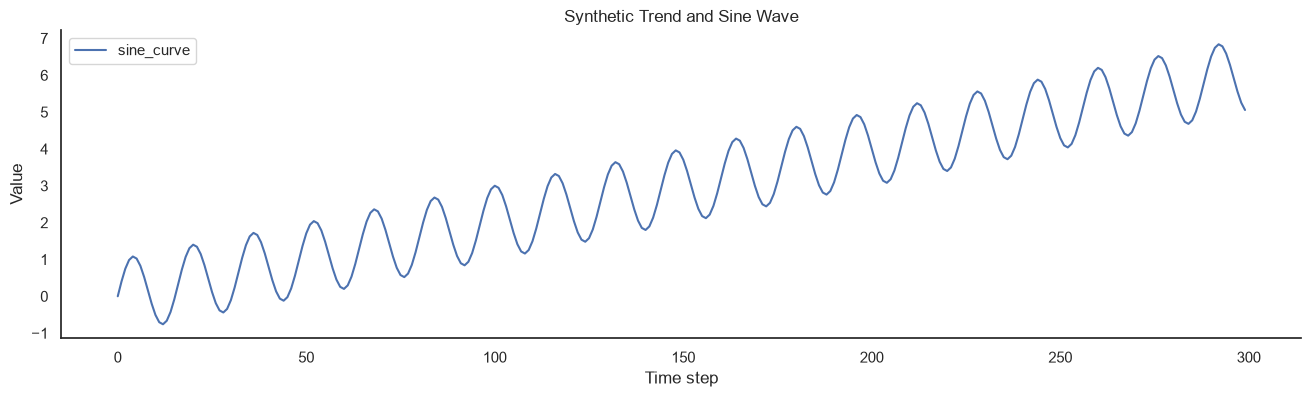

In [1]:
# A tutorial for this file is available at www.relataly.com
# Tested with Python 3.12, TensorFlow 2.21, Keras 3.15, pandas 3.0, and scikit-learn 1.9

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import RobustScaler

sns.set_theme(style="white", rc={"axes.spines.right": False, "axes.spines.top": False})
keras.utils.set_random_seed(42)

print(f"TensorFlow version: {tf.__version__}")
print(f"Available GPUs: {len(tf.config.list_physical_devices('GPU'))}")


def generate_signal(indices, gradient=0.02, frequency=0.125):
    indices = np.asarray(indices, dtype=np.float32)
    return gradient * indices + np.sin(np.pi * frequency * indices)


n_observations = 300
time_index = np.arange(n_observations)
df = pd.DataFrame({"sine_curve": generate_signal(time_index)}, index=time_index)

_, ax = plt.subplots(figsize=(16, 4))
sns.lineplot(data=df, ax=ax, color="#167D9A")
ax.set_title("Synthetic Trend and Sine Wave")
ax.set_xlabel("Time step")
ax.set_ylabel("Value")
plt.show()

# Step #2 Preprocessing

In [6]:
values = df[["sine_curve"]].to_numpy()
train_size = int(len(values) * 0.8)
changes = np.diff(values, axis=0)
train_change_count = train_size - 1

# Model changes rather than the trending level, and fit preprocessing on training changes only.
scaler = RobustScaler()
scaler.fit(changes[:train_change_count])
scaled_changes = scaler.transform(changes)

print(f"Training observations: {train_size}")
print(f"Test observations: {len(values) - train_size}")

Training observations: 240
Test observations: 60


In [7]:
sequence_length = 32


def create_sequences(series, sequence_length):
    features, targets = [], []
    for target_index in range(sequence_length, len(series)):
        features.append(series[target_index - sequence_length:target_index])
        targets.append(series[target_index, 0])

    return (
        np.asarray(features, dtype=np.float32),
        np.asarray(targets, dtype=np.float32),
    )


train_changes = scaled_changes[:train_change_count]
test_changes = scaled_changes[train_change_count - sequence_length:]
x_train, y_train = create_sequences(train_changes, sequence_length)
x_test, y_test = create_sequences(test_changes, sequence_length)
test_index = df.index[train_size:]

print(f"Training shapes: {x_train.shape}, {y_train.shape}")
print(f"Test shapes: {x_test.shape}, {y_test.shape}")

assert np.isclose(x_test[0, -1, 0], scaled_changes[train_change_count - 1, 0])
assert np.isclose(y_test[0], scaled_changes[train_change_count, 0])

Training shapes: (207, 32, 1), (207,)
Test shapes: (60, 32, 1), (60,)


# Step #3 Train the Model

In [8]:
model = keras.Sequential(
    [
        keras.layers.Input(shape=(sequence_length, 1)),
        keras.layers.LSTM(32),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1),
    ],
    name="recursive_sine_forecaster",
)
model.compile(optimizer=keras.optimizers.Adam(), loss="mean_squared_error")

epochs = 100
batch_size = 16
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)
history = model.fit(
    x_train,
    y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=0,
)

best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
print(f"Stopped after {len(history.history['loss'])} epochs")
print(f"Best validation epoch: {best_epoch}")

Stopped after 94 epochs
Best validation epoch: 84


# Step #4 Evaluate One-Step Predictions

In [ ]:
predicted_changes_scaled = model.predict(x_test, verbose=0)
predicted_changes = scaler.inverse_transform(predicted_changes_scaled).ravel()
actual_changes = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

forecast_origins = df["sine_curve"].iloc[train_size - 1:-1].to_numpy()
y_pred = forecast_origins + predicted_changes
y_test_unscaled = df["sine_curve"].iloc[train_size:].to_numpy()

absolute_percentage_errors = np.abs((y_test_unscaled - y_pred) / y_test_unscaled) * 100
mae = mean_absolute_error(y_test_unscaled, y_pred)
rmse = root_mean_squared_error(y_test_unscaled, y_pred)
mape = absolute_percentage_errors.mean()

# Persistence predicts no change from the latest observed value.
naive_pred = forecast_origins
naive_mae = mean_absolute_error(y_test_unscaled, naive_pred)
naive_rmse = root_mean_squared_error(y_test_unscaled, naive_pred)

print(f"LSTM one-step MAE: {mae:.4f}")
print(f"LSTM one-step RMSE: {rmse:.4f}")
print(f"LSTM one-step MAPE: {mape:.3f}%")
print(f"Persistence MAE: {naive_mae:.4f}")
print(f"Persistence RMSE: {naive_rmse:.4f}")

LSTM one-step MAE: 0.000
LSTM one-step RMSE: 0.000
LSTM one-step MAPE: 0.00%
Persistence MAE: 0.254
Persistence RMSE: 0.280


# Step #5 Visualizing Predictions and Loss

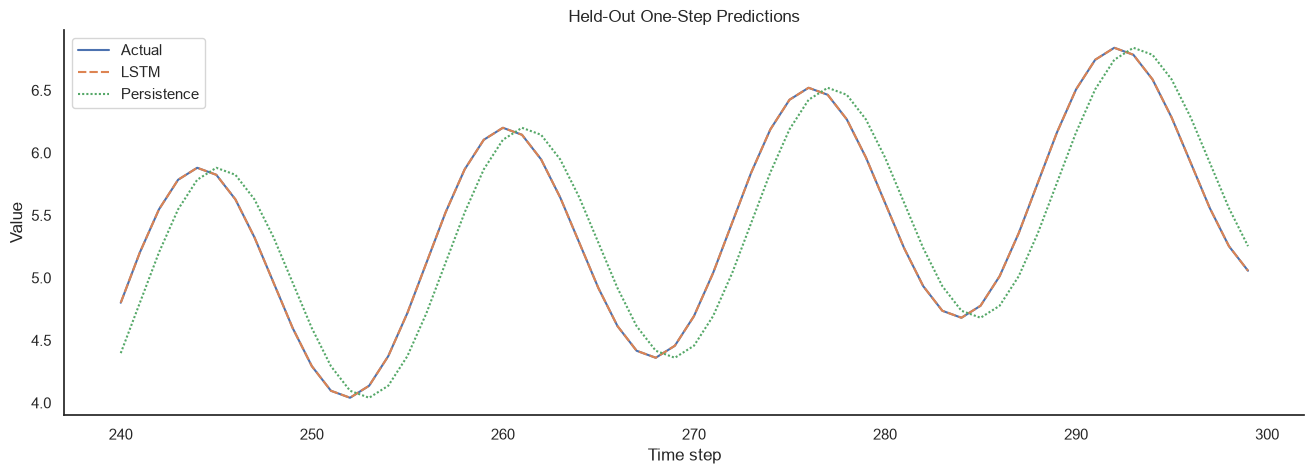

In [10]:
one_step_results = pd.DataFrame(
    {
        "Actual": y_test_unscaled,
        "LSTM": y_pred,
        "Persistence": naive_pred,
    },
    index=test_index,
)

_, ax = plt.subplots(figsize=(16, 5))
sns.lineplot(data=one_step_results, ax=ax)
ax.set_title("Held-Out One-Step Predictions")
ax.set_xlabel("Time step")
ax.set_ylabel("Value")
plt.show()

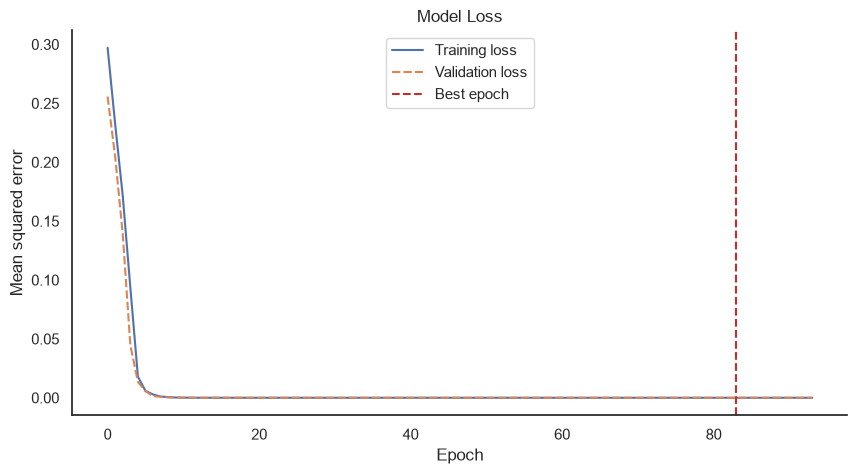

In [11]:
loss_history = pd.DataFrame(
    {
        "Training loss": history.history["loss"],
        "Validation loss": history.history["val_loss"],
    }
)

_, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=loss_history, ax=ax)
ax.axvline(best_epoch - 1, color="#C92A2A", linestyle="--", label="Best epoch")
ax.set_title("Model Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean squared error")
ax.legend()
plt.show()

# Step #6 Multi-step Time Series Predictions

In [12]:
forecast_steps = 30
rolling_scaled_changes = scaled_changes[-sequence_length:, 0].astype(np.float32).tolist()
forecast_changes_scaled = []

for _ in range(forecast_steps):
    x_input = np.asarray(
        rolling_scaled_changes[-sequence_length:],
        dtype=np.float32,
    ).reshape(1, sequence_length, 1)
    next_change_scaled = float(model.predict(x_input, verbose=0)[0, 0])
    forecast_changes_scaled.append(next_change_scaled)
    rolling_scaled_changes.append(next_change_scaled)

forecast_changes = scaler.inverse_transform(
    np.asarray(forecast_changes_scaled).reshape(-1, 1)
).ravel()
forecast_index = np.arange(n_observations, n_observations + forecast_steps)
forecast_values = float(values[-1, 0]) + np.cumsum(forecast_changes)
actual_future = generate_signal(forecast_index)
persistence_forecast = np.repeat(float(values[-1, 0]), forecast_steps)

rollout_mae = mean_absolute_error(actual_future, forecast_values)
rollout_rmse = root_mean_squared_error(actual_future, forecast_values)
persistence_rollout_mae = mean_absolute_error(actual_future, persistence_forecast)
persistence_rollout_rmse = root_mean_squared_error(actual_future, persistence_forecast)

forecast = pd.DataFrame(
    {
        "Actual future": actual_future,
        "Recursive LSTM": forecast_values,
        "Persistence": persistence_forecast,
    },
    index=forecast_index,
)

print(f"Recursive {forecast_steps}-step MAE: {rollout_mae:.4f}")
print(f"Recursive {forecast_steps}-step RMSE: {rollout_rmse:.4f}")
print(f"Persistence {forecast_steps}-step MAE: {persistence_rollout_mae:.4f}")
print(f"Persistence {forecast_steps}-step RMSE: {persistence_rollout_rmse:.4f}")

Recursive 30-step MAE: 0.0011
Recursive 30-step RMSE: 0.0013
Persistence 30-step MAE: 1.2920
Persistence 30-step RMSE: 1.4937


# Step #7 Visualize the Recursive Forecast

In [ ]:
forecast.head(10)

,sine_curve,y_pred,Forecast,y_pred_train
240,4.80000,4.795970,NaN,NaN
241,5.20268,5.191972,NaN,NaN
242,5.54711,5.532984,NaN,NaN
243,5.78388,5.770384,NaN,NaN
244,5.88000,5.869767,NaN,NaN
...,...,...,...,...
325,NaN,NaN,6.771809,NaN
326,NaN,NaN,6.642319,NaN
327,NaN,NaN,6.405490,NaN
328,NaN,NaN,6.096843,NaN


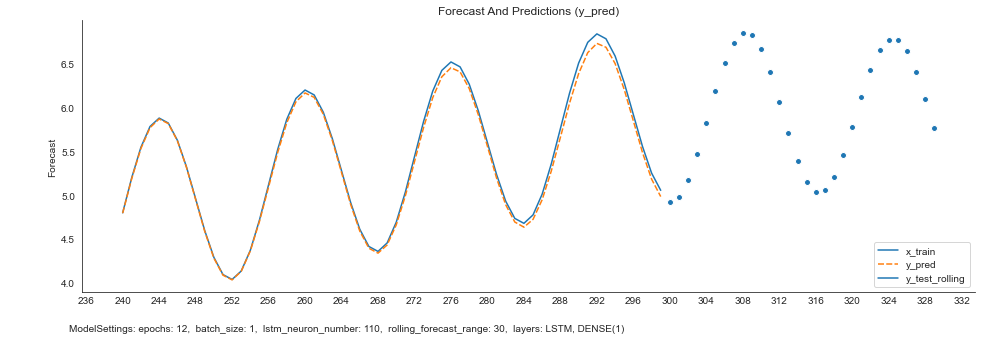

In [ ]:
history_window = df.iloc[-100:]

_, ax = plt.subplots(figsize=(16, 5))
sns.lineplot(
    x=history_window.index,
    y=history_window["sine_curve"],
    ax=ax,
    label="Observed",
)
sns.lineplot(
    x=forecast.index,
    y=forecast["Actual future"],
    ax=ax,
    color="black",
    linestyle="--",
    label="Actual future",
)
sns.lineplot(
    x=forecast.index,
    y=forecast["Recursive LSTM"],
    ax=ax,
    color="#C92A2A",
    marker="o",
    label="Recursive LSTM",
)
sns.lineplot(
    x=forecast.index,
    y=forecast["Persistence"],
    ax=ax,
    color="#2B8A3E",
    linestyle=":",
    label="Persistence",
)
ax.axvline(n_observations - 1, color="gray", linewidth=1)
ax.set_title("Thirty-Step Recursive Forecast")
ax.set_xlabel("Time step")
ax.set_ylabel("Value")
plt.show()